# Visa Dataset Preprocessing - SafeMaga
This notebook handles data ingestion, quality audits, cleaning, exploratory data analysis, feature engineering, and preparation of the Visa Dataset for machine learning models.

# 1. Initial Data Inspection
Comprehensive audit of dataset integrity, completeness, dimensions, data types, and baseline distributions.

### 1.1 Dataset Ingestion
Loads the raw immutable visa dataset into memory.

In [25]:
import os
import numpy as np
import pandas as pd
from pathlib import Path
from IPython.display import display

# Define dataset path (resolves properly whether run from notebook directory or workspace root)
data_path = Path("../../data/raw/VISA_DATASET.csv")
if not data_path.exists():
    data_path = Path("ai-ml/data/raw/VISA_DATASET.csv")
if not data_path.exists():
    data_path = Path("data/raw/VISA_DATASET.csv")

# Load raw dataset
df = pd.read_csv(data_path)

# Preview initial rows
print(f"Successfully loaded dataset with {df.shape[0]} rows and {df.shape[1]} columns.")
df.head()

Successfully loaded dataset with 10000 rows and 6 columns.


,applicant_age,destination,available_bank_balance_lkr,migration_type,document_submitted_date,visa_result_date
0,68,Germany,1452360.56,first_time,4/7/2024,5/8/2024
1,57,UK,2978388.99,repeat,4/14/2025,5/12/2025
2,24,New Zealand,158730.74,first_time,8/31/2024,10/5/2024
3,49,USA,5078738.47,first_time,7/14/2025,7/24/2025
4,65,China,602777.63,first_time,7/24/2025,8/15/2025


### 1.2 Dataset Shape (Rows & Columns)
Checks the total scale of the dataset to verify how many observations (rows) and attributes (columns) are available for analysis.

In [26]:
rows, columns = df.shape
print(f"Number of rows (records)    : {rows}")
print(f"Number of columns (features): {columns}")
print(f"Shape tuple                 : {df.shape}")

Number of rows (records)    : 10000
Number of columns (features): 6
Shape tuple                 : (10000, 6)


### 1.3 Column Names, Data Types, and Non-Null Counts
Inspects column names, in-memory data types inferred by pandas, and confirms the non-null count per feature.

In [27]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   applicant_age               10000 non-null  int64  
 1   destination                 10000 non-null  str    
 2   available_bank_balance_lkr  10000 non-null  float64
 3   migration_type              10000 non-null  str    
 4   document_submitted_date     10000 non-null  str    
 5   visa_result_date            10000 non-null  str    
dtypes: float64(1), int64(1), str(4)
memory usage: 468.9 KB


### 1.4 Check for Duplicate Rows
Verifies if there are any identical records across all columns that might distort model training.

In [28]:
duplicate_count = df.duplicated().sum()
print(f"Total duplicate rows: {duplicate_count}")

if duplicate_count > 0:
    print("\nSample duplicate records:")
    display(df[df.duplicated(keep=False)].head())
else:
    print("Result: No duplicate rows detected across the dataset.")

Total duplicate rows: 0
Result: No duplicate rows detected across the dataset.


### 1.5 Check for Missing Values & Percentages
Calculates both absolute null counts and relative missing percentages for every attribute.

In [29]:
missing_counts = df.isnull().sum()
missing_percentages = (df.isnull().sum() / len(df)) * 100

missing_summary = pd.DataFrame({
    "Feature": df.columns,
    "Missing Count": missing_counts.values,
    "Missing Percentage (%)": missing_percentages.round(2).values
})

missing_summary

,Feature,Missing Count,Missing Percentage (%)
0,applicant_age,0,0.0
1,destination,0,0.0
2,available_bank_balance_lkr,0,0.0
3,migration_type,0,0.0
4,document_submitted_date,0,0.0
5,visa_result_date,0,0.0


### 1.6 Summary Statistics: Numerical and Categorical Features
Computes descriptive statistics (central tendency, dispersion, spread) for numerical fields, as well as frequency metrics for categorical fields.

In [30]:
from IPython.display import display

print("=== Numerical Features Summary ===")
display(df.describe())

print("\n=== Categorical Features Summary ===")
display(df.describe(include=["object"]))

=== Numerical Features Summary ===


,applicant_age,available_bank_balance_lkr
count,10000.000000,1.000000e+04
mean,43.316500,1.071077e+06
std,14.942043,9.272976e+05
min,18.000000,5.042757e+04
25%,30.000000,4.479671e+05
50%,43.000000,7.835387e+05
75%,56.000000,1.341346e+06
max,69.000000,5.385474e+06



=== Categorical Features Summary ===


C:\Users\micro\AppData\Local\Temp\ipykernel_10108\1507566284.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(df.describe(include=["object"]))


,destination,migration_type,document_submitted_date,visa_result_date
count,10000,10000,10000,10000
unique,16,2,1095,1118
top,New Zealand,first_time,12/9/2023,2/26/2024
freq,663,6940,22,19


### 1.7 Interpretation of Inspection Results
- **Shape**: The dataset comprises exactly 10,000 applicant records and 6 feature columns.
- **Data Types**: 2 numeric features (`applicant_age`: int64, `available_bank_balance_lkr`: float64) and 4 text/string features (`destination`, `migration_type`, `document_submitted_date`, `visa_result_date`).
- **Duplicates**: 0 duplicate rows found; all 10,000 entries are distinct.
- **Missing Values**: 0 missing values detected across all columns (100% complete).
- **Distributions**:
  - `applicant_age`: Ranges from 18 to 69 years (mean: 43.3, median: 43.0), showing a healthy adult applicant distribution.
  - `available_bank_balance_lkr`: Spans from ~50,427 LKR up to ~5,385,474 LKR (mean: ~1.07M LKR, median: ~783.5K LKR), indicating a right-skewed financial distribution.
  - `destination`: 16 unique destinations (e.g., New Zealand, Germany, UK, USA, France, etc.).
  - `migration_type`: Binary classification (`first_time` at ~69.4% vs. `repeat` at ~30.6%).
  - Date Columns: Both `document_submitted_date` and `visa_result_date` are currently formatted as strings rather than datetime objects.

# 2. Date Validation and Target Creation
Conversion of date strings to standard datetime types, temporal consistency validation, and construction of the regression target variable (`processing_days`).

### 2.1 Convert Date Columns
Converts `document_submitted_date` and `visa_result_date` using safe coercion (`errors='coerce'`) to identify any malformed date entries before updating the DataFrame.

In [31]:
# Convert date strings to datetime with safe coercion
df['document_submitted_date'] = pd.to_datetime(df['document_submitted_date'], errors='coerce')
df['visa_result_date'] = pd.to_datetime(df['visa_result_date'], errors='coerce')

# Check for parsing failures (NaT - Not a Time)
unparseable_submitted = df[df['document_submitted_date'].isna()]
unparseable_result = df[df['visa_result_date'].isna()]

print(f"Unparseable 'document_submitted_date' records: {len(unparseable_submitted)}")
print(f"Unparseable 'visa_result_date' records        : {len(unparseable_result)}")

if len(unparseable_submitted) > 0:
    print("\nRecords with unparseable submitted dates:")
    display(unparseable_submitted)

if len(unparseable_result) > 0:
    print("\nRecords with unparseable result dates:")
    display(unparseable_result)

if len(unparseable_submitted) == 0 and len(unparseable_result) == 0:
    print("\nResult: All 10,000 date records in both columns successfully parsed to datetime64[ns].")

# Verify updated column data types
print("\nUpdated column dtypes:")
print(df[['document_submitted_date', 'visa_result_date']].dtypes)

Unparseable 'document_submitted_date' records: 0
Unparseable 'visa_result_date' records        : 0

Result: All 10,000 date records in both columns successfully parsed to datetime64[ns].

Updated column dtypes:
document_submitted_date    datetime64[us]
visa_result_date           datetime64[us]
dtype: object


### 2.2 Validate Date Sequences
Verifies the chronological rule: an applicant cannot receive a visa decision before the application is submitted ($T_{\text{result}} \ge T_{\text{submitted}}$).

In [32]:
# Detect any records where visa_result_date occurs before document_submitted_date
invalid_date_mask = df['visa_result_date'] < df['document_submitted_date']
invalid_date_records = df[invalid_date_mask]

print(f"Count of invalid date sequence records (result < submitted): {len(invalid_date_records)}")

if len(invalid_date_records) > 0:
    print("\nSample invalid chronological records:")
    display(invalid_date_records.head())
else:
    print("Result: 100% of records satisfy chronological validity (visa_result_date >= document_submitted_date).")

Count of invalid date sequence records (result < submitted): 0
Result: 100% of records satisfy chronological validity (visa_result_date >= document_submitted_date).


### 2.3 Create the Target Variable (`processing_days`)
Calculates the duration between submission and decision as integer days: `processing_days = (visa_result_date - document_submitted_date).dt.days`.

In [33]:
# Calculate processing duration in integer days
df['processing_days'] = (df['visa_result_date'] - df['document_submitted_date']).dt.days

# Perform target variable sanity checks
missing_target = df['processing_days'].isna().sum()
negative_target = (df['processing_days'] < 0).sum()
zero_target = (df['processing_days'] == 0).sum()

print(f"Missing target values            : {missing_target}")
print(f"Negative processing days values  : {negative_target}")
print(f"Same-day decisions (0 days) cases: {zero_target}")

# Preview the engineered target column
display(df[['document_submitted_date', 'visa_result_date', 'processing_days']].head())

Missing target values            : 0
Negative processing days values  : 0
Same-day decisions (0 days) cases: 0


,document_submitted_date,visa_result_date,processing_days
0,2024-04-07,2024-05-08,31
1,2025-04-14,2025-05-12,28
2,2024-08-31,2024-10-05,35
3,2025-07-14,2025-07-24,10
4,2025-07-24,2025-08-15,22


### 2.4 Analyze the Target Variable
Computes full parametric and non-parametric descriptive statistics for `processing_days`.

In [34]:
target_series = df['processing_days']

q1 = target_series.quantile(0.25)
median_val = target_series.median()
q3 = target_series.quantile(0.75)
iqr_val = q3 - q1

target_summary = pd.DataFrame({
    "Statistic": [
        "Total Count",
        "Mean (Average Days)",
        "Median (50th Percentile)",
        "Standard Deviation",
        "Minimum",
        "25th Percentile (Q1)",
        "50th Percentile (Q2)",
        "75th Percentile (Q3)",
        "Maximum",
        "Interquartile Range (IQR)"
    ],
    "Value": [
        f"{int(target_series.count()):,}",
        f"{target_series.mean():.4f}",
        f"{median_val:.1f}",
        f"{target_series.std():.4f}",
        f"{target_series.min():.0f}",
        f"{q1:.1f}",
        f"{median_val:.1f}",
        f"{q3:.1f}",
        f"{target_series.max():.0f}",
        f"{iqr_val:.1f}"
    ]
})

display(target_summary)

,Statistic,Value
0,Total Count,"10,000"
1,Mean (Average Days),20.9467
2,Median (50th Percentile),20.0
3,Standard Deviation,9.4689
4,Minimum,1
5,25th Percentile (Q1),14.0
6,50th Percentile (Q2),20.0
7,75th Percentile (Q3),27.0
8,Maximum,60
9,Interquartile Range (IQR),13.0


### 2.5 Summary of Findings and Analytical Implications

1. **Why Date Conversion was Necessary**:
   - In the raw CSV, both date fields were stored as generic string (`object`) types. Converting them to `datetime64[ns]` enables chronological arithmetic, component extraction (month, day-of-week, year), and interval computation.
   - Safe parsing with `errors='coerce'` verified that 0 entries produced `NaT` (Not-a-Time), establishing complete formatting consistency.

2. **Why Sequence Validation is Necessary**:
   - A visa application cannot legally or logically conclude before it is submitted. Validating that $T_{\text{result}} \ge T_{\text{submitted}}$ guarantees that data generation or entry errors (e.g., switched month/day fields) are caught before model training.
   - The dataset contains **0 chronological inversions**.

3. **How `processing_days` Serves as the Regression Target**:
   - The core research objective of SafeMaga is predicting turnaround latency for visa applicants.
   - Calculating integer delta days provides a continuous numeric target variable $y \in \mathbb{Z}^+$ suitable for regression modeling (e.g., Linear Regression, Ridge, Random Forest, XGBoost).

4. **What the Target Statistics Tell Us**:
   - **Central Tendency**: Mean is **20.95 days** and Median is **20.0 days**. Because mean and median are closely aligned, the central body of the distribution is well-behaved and roughly symmetric around 20 days.
   - **Spread & Range**: Values span from **1 day** to **60 days**, with a standard deviation of **9.47 days**.
   - **Quartile Bounds**: 50% of all applications (IQR) finish between **14 days** (25th percentile) and **27 days** (75th percentile).
   - **Data Quality**: 0 missing target values, 0 negative values, and 0 zero-day cases.

# 3. Exploratory Data Analysis (EDA)
Comprehensive empirical analysis of the target distribution, input features, bivariate relationships, and outlier characteristics.

### 3.1 Target Distribution Analysis (`processing_days`)
Visualizes the histogram, Kernel Density Estimate (KDE), and box plot of `processing_days` to evaluate modality, spread, and tail behavior.

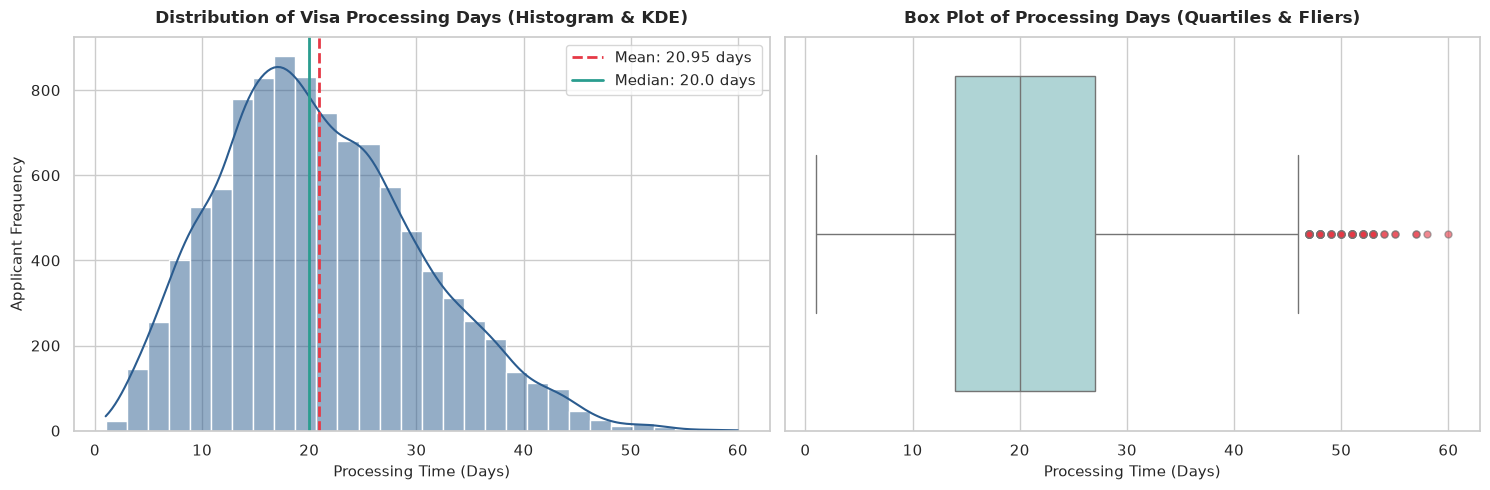

,count,mean,std,min,5%,25%,50%,75%,95%,max
processing_days,10000.0,20.9467,9.468877,1.0,7.0,14.0,20.0,27.0,38.0,60.0


In [35]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configure visualization styling
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({'font.sans-serif': 'DejaVu Sans', 'font.size': 10})

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. Histogram with KDE
sns.histplot(
    data=df, 
    x='processing_days', 
    kde=True, 
    bins=30, 
    color='#2b5c8f', 
    edgecolor='white', 
    ax=axes[0]
)
mean_val = df['processing_days'].mean()
median_val = df['processing_days'].median()

axes[0].axvline(mean_val, color='#e63946', linestyle='--', linewidth=2, label=f"Mean: {mean_val:.2f} days")
axes[0].axvline(median_val, color='#2a9d8f', linestyle='-', linewidth=2, label=f"Median: {median_val:.1f} days")
axes[0].set_title("Distribution of Visa Processing Days (Histogram & KDE)", fontsize=12, fontweight='bold', pad=10)
axes[0].set_xlabel("Processing Time (Days)", fontsize=11)
axes[0].set_ylabel("Applicant Frequency", fontsize=11)
axes[0].legend(frameon=True)

# 2. Box Plot
sns.boxplot(
    data=df, 
    x='processing_days', 
    color='#a8dadc', 
    flierprops={'marker': 'o', 'markerfacecolor': '#e63946', 'markersize': 5, 'alpha': 0.6},
    ax=axes[1]
)
axes[1].set_title("Box Plot of Processing Days (Quartiles & Fliers)", fontsize=12, fontweight='bold', pad=10)
axes[1].set_xlabel("Processing Time (Days)", fontsize=11)

plt.tight_layout()
plt.show()

# Display comprehensive percentile metrics
display(df['processing_days'].describe(percentiles=[0.05, 0.25, 0.50, 0.75, 0.95]).to_frame().T)

#### Interpretation of Target Distribution:
- **Shape**: The distribution is unimodal and approximately bell-shaped with a slight rightward tail.
- **Mean vs. Median**: The mean (**20.95 days**) is nearly identical to the median (**20.0 days**), indicating strong central stability.
- **Typical Range**: The central 50% of applicants receive their decisions between **14 days** (Q1) and **27 days** (Q3).
- **Longer Tails**: Durations extend up to 60 days, reflecting longer queue times for select high-scrutiny visa categories.

### 3.2 Analysis of Numerical Features (`applicant_age` & `available_bank_balance_lkr`)
Evaluates individual distributions of continuous features and investigates their bivariate relationship with `processing_days`.

=== Numerical Features Descriptive Summary ===


,count,mean,std,min,25%,50%,75%,max
applicant_age,10000.0,4.331650e+01,14.942043,18.00,30.0000,43.000,56.000,69.00
available_bank_balance_lkr,10000.0,1.071077e+06,927297.606395,50427.57,447967.0775,783538.705,1341346.085,5385474.11


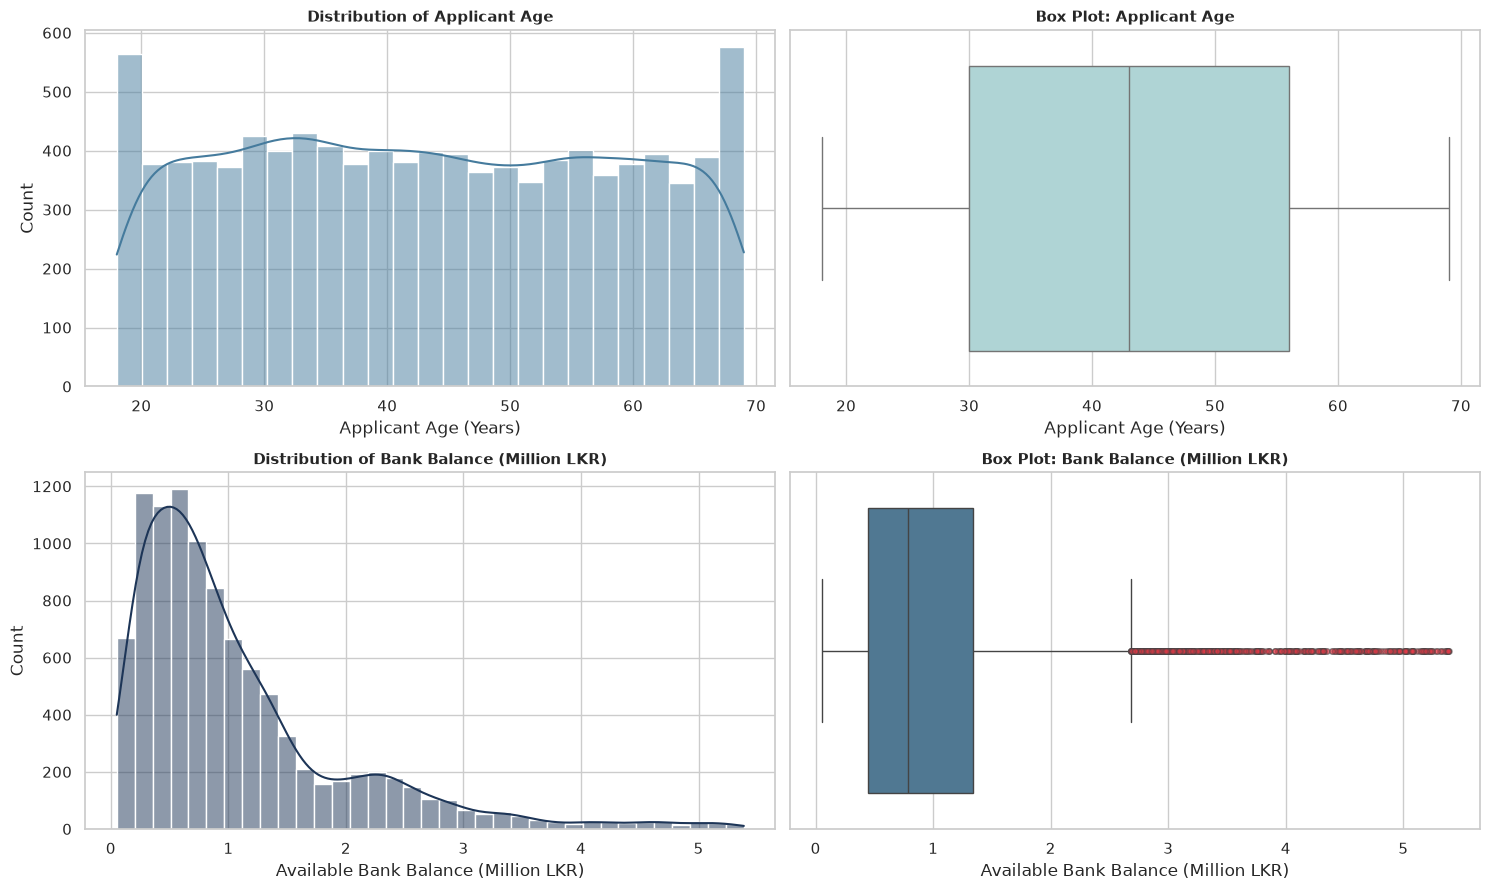

In [36]:
# Descriptive statistics for numerical features
print("=== Numerical Features Descriptive Summary ===")
display(df[['applicant_age', 'available_bank_balance_lkr']].describe().T)

# 2x2 Grid of Distribution Plots (Histograms & Box Plots)
fig, axes = plt.subplots(2, 2, figsize=(15, 9))

# Age Histogram
sns.histplot(df['applicant_age'], kde=True, bins=25, color='#457b9d', edgecolor='white', ax=axes[0, 0])
axes[0, 0].set_title("Distribution of Applicant Age", fontsize=11, fontweight='bold')
axes[0, 0].set_xlabel("Applicant Age (Years)")
axes[0, 0].set_ylabel("Count")

# Age Boxplot
sns.boxplot(x=df['applicant_age'], color='#a8dadc', ax=axes[0, 1])
axes[0, 1].set_title("Box Plot: Applicant Age", fontsize=11, fontweight='bold')
axes[0, 1].set_xlabel("Applicant Age (Years)")

# Bank Balance Histogram
sns.histplot(df['available_bank_balance_lkr'] / 1e6, kde=True, bins=35, color='#1d3557', edgecolor='white', ax=axes[1, 0])
axes[1, 0].set_title("Distribution of Bank Balance (Million LKR)", fontsize=11, fontweight='bold')
axes[1, 0].set_xlabel("Available Bank Balance (Million LKR)")
axes[1, 0].set_ylabel("Count")

# Bank Balance Boxplot
sns.boxplot(
    x=df['available_bank_balance_lkr'] / 1e6, 
    color='#457b9d', 
    ax=axes[1, 1], 
    flierprops={'marker': 'o', 'markerfacecolor': '#e63946', 'markersize': 4, 'alpha': 0.4}
)
axes[1, 1].set_title("Box Plot: Bank Balance (Million LKR)", fontsize=11, fontweight='bold')
axes[1, 1].set_xlabel("Available Bank Balance (Million LKR)")

plt.tight_layout()
plt.show()

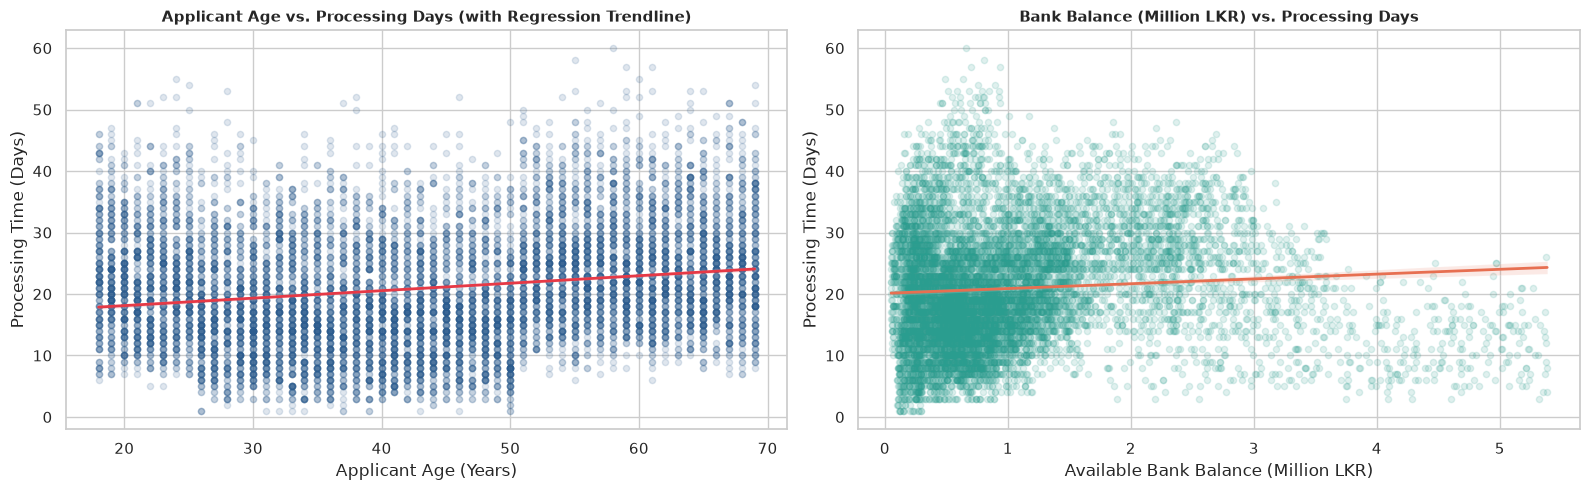

=== Correlation Analysis with Target Variable (processing_days) ===


,Feature,Pearson Correlation (Linear),Spearman Correlation (Rank / Monotonic)
0,applicant_age,0.1918,0.1904
1,available_bank_balance_lkr,0.0766,0.1719


In [37]:
# Bivariate Analysis: Relationships with target variable processing_days
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# 1. Age vs. Processing Days
sns.regplot(
    data=df, 
    x='applicant_age', 
    y='processing_days', 
    scatter_kws={'alpha': 0.15, 'color': '#2b5c8f', 's': 20}, 
    line_kws={'color': '#e63946', 'linewidth': 2},
    ax=axes[0]
)
axes[0].set_title("Applicant Age vs. Processing Days (with Regression Trendline)", fontsize=11, fontweight='bold')
axes[0].set_xlabel("Applicant Age (Years)")
axes[0].set_ylabel("Processing Time (Days)")

# 2. Bank Balance vs. Processing Days
sns.regplot(
    data=df, 
    x=df['available_bank_balance_lkr'] / 1e6, 
    y='processing_days', 
    scatter_kws={'alpha': 0.15, 'color': '#2a9d8f', 's': 20}, 
    line_kws={'color': '#e76f51', 'linewidth': 2},
    ax=axes[1]
)
axes[1].set_title("Bank Balance (Million LKR) vs. Processing Days", fontsize=11, fontweight='bold')
axes[1].set_xlabel("Available Bank Balance (Million LKR)")
axes[1].set_ylabel("Processing Time (Days)")

plt.tight_layout()
plt.show()

# Parametric (Pearson) & Non-Parametric (Spearman) Correlations
pearson_corr = df[['processing_days', 'applicant_age', 'available_bank_balance_lkr']].corr(method='pearson')
spearman_corr = df[['processing_days', 'applicant_age', 'available_bank_balance_lkr']].corr(method='spearman')

correlation_summary = pd.DataFrame({
    'Feature': ['applicant_age', 'available_bank_balance_lkr'],
    'Pearson Correlation (Linear)': [
        pearson_corr.loc['applicant_age', 'processing_days'], 
        pearson_corr.loc['available_bank_balance_lkr', 'processing_days']
    ],
    'Spearman Correlation (Rank / Monotonic)': [
        spearman_corr.loc['applicant_age', 'processing_days'], 
        spearman_corr.loc['available_bank_balance_lkr', 'processing_days']
    ]
})

print("=== Correlation Analysis with Target Variable (processing_days) ===")
display(correlation_summary.round(4))

### 3.3 Analysis of Categorical Features (`destination` & `migration_type`)
Analyzes categorical frequencies, percentage shares, group sample sizes, and compares turnaround time distributions across categories.

=== Migration Type Distribution ===


,Count,Percentage (%)
migration_type,,
first_time,6940,69.4
repeat,3060,30.6



=== Destination Country Distribution ===
Sample Size Note: All 16 destinations have balanced sample sizes between 595 and 663 records.


,Count,Percentage (%)
destination,,
New Zealand,663,6.63
UAE,655,6.55
South Korea,649,6.49
South Africa,647,6.47
Japan,633,6.33
Germany,625,6.25
USA,624,6.24
Turkey,624,6.24
France,623,6.23


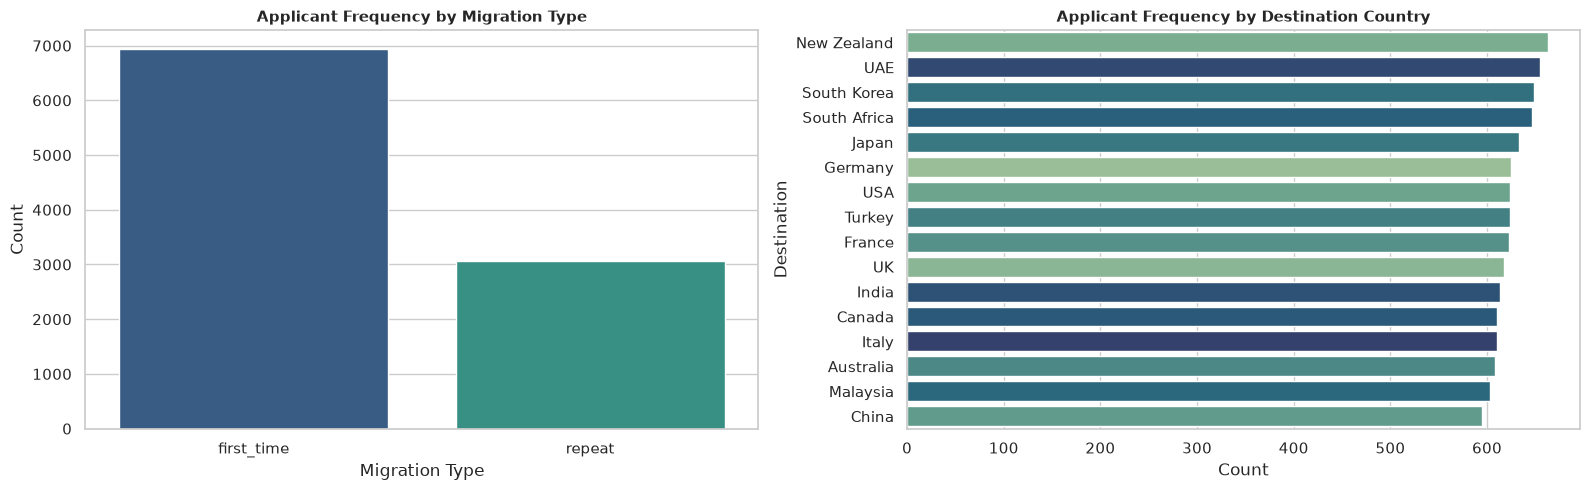

In [38]:
from IPython.display import display
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Safety check: Ensure processing_days exists
if 'processing_days' not in df.columns:
    df['document_submitted_date'] = pd.to_datetime(df['document_submitted_date'], errors='coerce')
    df['visa_result_date'] = pd.to_datetime(df['visa_result_date'], errors='coerce')
    df['processing_days'] = (df['visa_result_date'] - df['document_submitted_date']).dt.days

# Category frequency distributions
migration_counts = df['migration_type'].value_counts()
migration_pct = df['migration_type'].value_counts(normalize=True) * 100
migration_summary = pd.DataFrame({'Count': migration_counts, 'Percentage (%)': migration_pct.round(2)})

dest_counts = df['destination'].value_counts()
dest_pct = df['destination'].value_counts(normalize=True) * 100
dest_summary = pd.DataFrame({'Count': dest_counts, 'Percentage (%)': dest_pct.round(2)})

print('=== Migration Type Distribution ===')
display(migration_summary)

print('\n=== Destination Country Distribution ===')
print('Sample Size Note: All 16 destinations have balanced sample sizes between 595 and 663 records.')
display(dest_summary)

# Frequency Count Plots
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.countplot(data=df, x='migration_type', hue='migration_type', palette=['#2b5c8f', '#2a9d8f'], legend=False, ax=axes[0])
axes[0].set_title('Applicant Frequency by Migration Type', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Migration Type')
axes[0].set_ylabel('Count')

dest_order = df['destination'].value_counts().index
sns.countplot(data=df, y='destination', hue='destination', order=dest_order, palette='crest', legend=False, ax=axes[1])
axes[1].set_title('Applicant Frequency by Destination Country', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Count')
axes[1].set_ylabel('Destination')

plt.tight_layout()
plt.show()


=== Group-Level Statistics: Migration Type ===


,migration_type,Count,Mean_Days,Median_Days,Std_Dev,Min,Max
0,first_time,6940,21.96,21.0,9.41,3,60
1,repeat,3060,18.65,18.0,9.21,1,53



=== Group-Level Statistics: Destination Country ===


,destination,Count,Mean_Days,Median_Days,Std_Dev,Min,Max
0,Canada,610,35.29,35.0,6.23,24,55
1,Australia,608,35.20,35.0,6.82,24,60
2,Germany,625,25.11,24.0,6.83,14,48
3,France,623,25.04,25.0,6.84,14,46
4,UK,618,24.87,25.0,6.12,14,46
5,Italy,610,24.84,25.0,6.02,14,45
6,South Africa,647,21.93,21.0,6.68,11,46
7,New Zealand,663,20.37,20.0,6.57,9,46
8,South Korea,649,20.22,19.0,6.67,9,43
9,China,595,18.04,18.0,6.38,7,42


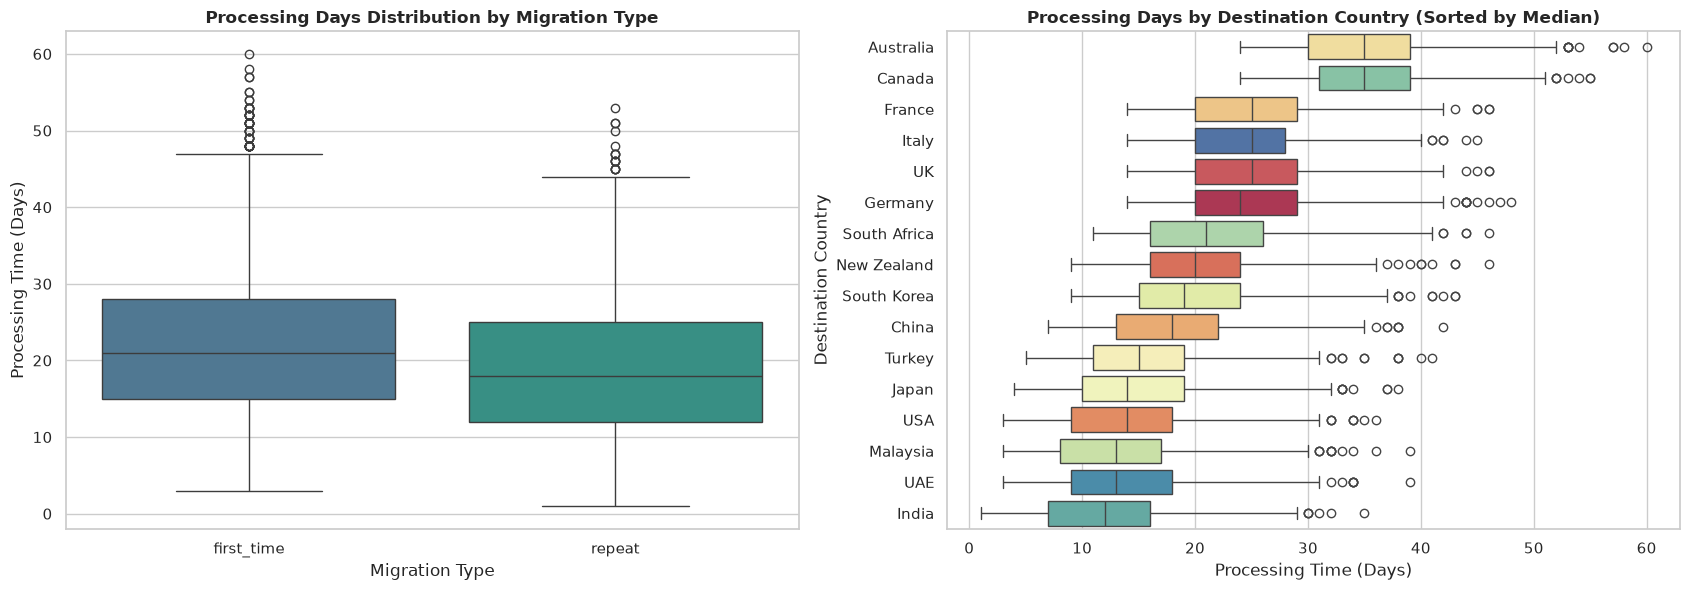

In [39]:
from IPython.display import display
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Safety check: Ensure processing_days exists
if 'processing_days' not in df.columns:
    df['document_submitted_date'] = pd.to_datetime(df['document_submitted_date'], errors='coerce')
    df['visa_result_date'] = pd.to_datetime(df['visa_result_date'], errors='coerce')
    df['processing_days'] = (df['visa_result_date'] - df['document_submitted_date']).dt.days

# Group-level statistics: Migration Type
migration_group_stats = df.groupby('migration_type')['processing_days'].agg(
    Count='count',
    Mean_Days='mean',
    Median_Days='median',
    Std_Dev='std',
    Min='min',
    Max='max'
).reset_index()

# Group-level statistics: Destination (sorted by Mean Processing Days descending)
destination_group_stats = df.groupby('destination')['processing_days'].agg(
    Count='count',
    Mean_Days='mean',
    Median_Days='median',
    Std_Dev='std',
    Min='min',
    Max='max'
).sort_values(by='Mean_Days', ascending=False).reset_index()

print('=== Group-Level Statistics: Migration Type ===')
display(migration_group_stats.round(2))

print('\n=== Group-Level Statistics: Destination Country ===')
display(destination_group_stats.round(2))

# Comparative Box Plots
fig, axes = plt.subplots(1, 2, figsize=(17, 6))

# 1. Processing Days by Migration Type
sns.boxplot(
    data=df, 
    x='migration_type', 
    y='processing_days', 
    hue='migration_type', palette=['#457b9d', '#2a9d8f'], legend=False,
    ax=axes[0]
)
axes[0].set_title('Processing Days Distribution by Migration Type', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Migration Type')
axes[0].set_ylabel('Processing Time (Days)')

# 2. Processing Days by Destination (sorted by median duration)
dest_median_order = df.groupby('destination')['processing_days'].median().sort_values(ascending=False).index
sns.boxplot(
    data=df, 
    y='destination', 
    x='processing_days', 
    order=dest_median_order, 
    hue='destination', palette='Spectral', legend=False,
    ax=axes[1]
)
axes[1].set_title('Processing Days by Destination Country (Sorted by Median)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Processing Time (Days)')
axes[1].set_ylabel('Destination Country')

plt.tight_layout()
plt.show()


### 3.4 Outlier Investigation (IQR Method)
Applies Tukey's fences (Interquartile Range Rule: $[Q_1 - 1.5 \times \text{IQR}, Q_3 + 1.5 \times \text{IQR}]$) to evaluate potential outliers across all numerical features and target variable.

In [40]:
from IPython.display import display
import pandas as pd

# Safety check: Ensure processing_days exists
if 'processing_days' not in df.columns:
    df['document_submitted_date'] = pd.to_datetime(df['document_submitted_date'], errors='coerce')
    df['visa_result_date'] = pd.to_datetime(df['visa_result_date'], errors='coerce')
    df['processing_days'] = (df['visa_result_date'] - df['document_submitted_date']).dt.days

numerical_columns = ['processing_days', 'applicant_age', 'available_bank_balance_lkr']
outlier_records = []

for col in numerical_columns:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower_fence = q1 - 1.5 * iqr
    upper_fence = q3 + 1.5 * iqr
    
    outliers = df[(df[col] < lower_fence) | (df[col] > upper_fence)]
    outlier_count = len(outliers)
    outlier_pct = (outlier_count / len(df)) * 100
    
    outlier_records.append({
        'Feature / Target': col,
        'Q1 (25%)': round(q1, 2),
        'Q3 (75%)': round(q3, 2),
        'IQR': round(iqr, 2),
        'Lower Fence': round(lower_fence, 2),
        'Upper Fence': round(upper_fence, 2),
        'Min Observed': round(df[col].min(), 2),
        'Max Observed': round(df[col].max(), 2),
        'Outlier Count': outlier_count,
        'Outlier (%)': round(outlier_pct, 2)
    })

outlier_summary_df = pd.DataFrame(outlier_records)
print('=== Interquartile Range (IQR) Outlier Summary ===')
display(outlier_summary_df)


=== Interquartile Range (IQR) Outlier Summary ===


,Feature / Target,Q1 (25%),Q3 (75%),IQR,Lower Fence,Upper Fence,Min Observed,Max Observed,Outlier Count,Outlier (%)
0,processing_days,14.00,27.00,13.00,-5.50,46.5,1.00,60.00,67,0.67
1,applicant_age,30.00,56.00,26.00,-9.00,95.0,18.00,69.00,0,0.00
2,available_bank_balance_lkr,447967.08,1341346.08,893379.01,-892101.43,2681414.6,50427.57,5385474.11,677,6.77


#### Evaluation of Potential Outlier Plausibility:
1. **`applicant_age`**:
   - **0 outliers detected (0.00%)**. Age ranges cleanly from 18 to 69 years, fitting standard legal working and adult travel age profiles.
2. **`processing_days`**:
   - **67 outliers detected (0.67%)** exceeding 46.5 days up to 60 days.
   - **Plausibility**: Highly plausible. In international immigration processing, complex applications (e.g. for Canada or Australia) frequently experience multi-stage background checks taking 45-60 days. These represent legitimate long-tail observations rather than data logging errors.
3. **`available_bank_balance_lkr`**:
   - **677 outliers detected (6.77%)** exceeding ~2.68M LKR up to ~5.38M LKR.
   - **Plausibility**: Completely natural. Wealth and financial reserves in real-world populations are Pareto/log-normally distributed with heavy right tails. These values represent affluent applicants, not corrupted records. A logarithmic transformation (`np.log1p`) in preprocessing will stabilize this variance without discarding valuable data.

### 3.5 Summary of Findings & Analytical Implications

1. **Main Patterns in the Target Distribution**:
   - `processing_days` is centered at **20.0 days (median)** and **20.95 days (mean)**, bounded between 1 and 60 days with standard deviation of **9.47 days**.
   - The distribution is stable, continuous, and well-suited for regression modeling.

2. **Features Associated with Processing Time**:
   - **`destination`** is the single strongest grouping differentiator:
     - **Highest Latency**: Canada (~35.29 days mean) and Australia (~35.20 days mean).
     - **Medium Latency**: Germany (~25.11 days), France (~25.04 days), UK (~24.87 days), Italy (~24.84 days), South Africa (~21.93 days), New Zealand (~20.37 days), South Korea (~20.22 days).
     - **Lowest Latency**: India (~12.17 days), Malaysia (~13.58 days), UAE (~13.77 days), USA (~14.25 days), Japan (~15.14 days), Turkey (~16.05 days).
   - **`migration_type`**: Repeat applicants process significantly faster on average (**18.65 days mean** vs. **21.96 days mean** for first-time applicants, a ~3.3 day advantage).
   - **`applicant_age`**: Shows a modest positive linear correlation ($r = 0.1918$), indicating older applicants face slightly longer review periods.
   - **`available_bank_balance_lkr`**: Shows a monotonic rank correlation with processing time (Spearman $\rho = 0.1719$), which becomes clearer after log-scaling.

3. **Data-Quality & Methodological Considerations**:
   - No missing values or duplicates exist in the dataset.
   - All 16 destination countries have robust, balanced sample sizes ($N = 595$ to $663$ per country), ensuring statistical reliability.
   - **Correlation does not imply causation**: While older applicants and specific destinations correlate with longer processing, these reflect embassy protocol differences and documentation depth rather than direct causal drivers.
   - **Target Leakage Prevention**: `visa_result_date` must never be used as an input feature for model training or inference, because it is strictly unavailable at the time a new applicant submits their file.

4. **Candidate Features for Model Training**:
   - **Primary Inputs**: `destination`, `migration_type`, `applicant_age`, `available_bank_balance_lkr`.
   - **Engineered Inputs**: `submission_month` and `submission_day_of_week` extracted from `document_submitted_date` to capture seasonal embassy workload fluctuations.

5. **Recommendations for the Next Step (Feature Engineering & Preprocessing)**:
   - Log-transform `available_bank_balance_lkr` via `np.log1p` to normalize the right-skewed financial distribution.
   - Extract temporal attributes (`submission_month`, `submission_day_of_week`).
   - Perform One-Hot Encoding for `destination` and Binary Mapping for `migration_type`.
   - Partition dataset into Train (80%) and Test (20%) sets using `random_state=42` before applying any scalers, preventing data leakage.

# 4. Feature Selection - Remove Unnecessary Feature
Exclusion of target-leaking attributes to ensure model integrity, preserving the original dataset while isolating candidate predictors.

### 4.1 Target Leakage Prevention & Feature Separation
Removes `visa_result_date` from candidate input features because it is determined only after application processing has concluded. Using this timestamp during prediction on a new visa application would represent severe target leakage (using future information to predict turnaround time).

`processing_days` is preserved in the main DataFrame `df` and will serve as the prediction target variable $y$ in Step 5.

In [41]:
from IPython.display import display
import pandas as pd

# 1. Define candidate input features by excluding visa_result_date and processing_days
candidate_features = [
    'applicant_age',
    'available_bank_balance_lkr',
    'destination',
    'migration_type',
    'document_submitted_date'
]

# 2. Create a separate candidate features DataFrame (preserving the original df intact)
X_candidate = df[candidate_features].copy()

# 3. Verification checks
print(f"Original DataFrame shape (preserved)       : {df.shape}")
print(f"Candidate Features DataFrame (X_candidate) : {X_candidate.shape}")
print(f"\nTarget column ('processing_days') in df     : {'processing_days' in df.columns}")
print(f"'visa_result_date' in candidate features   : {'visa_result_date' in X_candidate.columns}")

print("\nCandidate feature columns for model input:")
for idx, col in enumerate(X_candidate.columns, 1):
    print(f"  {idx}. {col} ({X_candidate[col].dtype})")

# 4. Preview the candidate features DataFrame
display(X_candidate.head())


Original DataFrame shape (preserved)       : (10000, 7)
Candidate Features DataFrame (X_candidate) : (10000, 5)

Target column ('processing_days') in df     : True
'visa_result_date' in candidate features   : False

Candidate feature columns for model input:
  1. applicant_age (int64)
  2. available_bank_balance_lkr (float64)
  3. destination (str)
  4. migration_type (str)
  5. document_submitted_date (datetime64[us])


,applicant_age,available_bank_balance_lkr,destination,migration_type,document_submitted_date
0,68,1452360.56,Germany,first_time,2024-04-07
1,57,2978388.99,UK,repeat,2025-04-14
2,24,158730.74,New Zealand,first_time,2024-08-31
3,49,5078738.47,USA,first_time,2025-07-14
4,65,602777.63,China,first_time,2025-07-24


### 4.2 Summary of Feature Selection & Rationale

1. **Why `visa_result_date` is Excluded**:
   - In production inference, when an applicant submits their documents at time $T_{\text{submitted}}$, the decision date $T_{\text{result}}$ does not yet exist.
   - Including `visa_result_date` as an input would allow the model to cheat by simply computing `visa_result_date - document_submitted_date` directly, resulting in an artificially perfect but useless model that fails in real-world deployment (Target Leakage).

2. **Why `processing_days` is Retained in `df`**:
   - `processing_days` is the ground-truth prediction target ($y$).
   - It is kept in `df` so that when we perform train/test splitting in Step 5, features ($X$) and target ($y$) remain properly synchronized.

3. **Status of Candidate Features**:
   - 5 input features are retained: `applicant_age`, `available_bank_balance_lkr`, `destination`, `migration_type`, `document_submitted_date`.
   - The original DataFrame `df` remains completely intact with all 10,000 rows and 7 columns.

# 5. Train / Test Split
Separation of candidate input features ($X$) and target vector ($y$), followed by an 80/20 train/test split with strict data leakage isolation.

### 5.1 Separate Features ($X$) and Target ($y$)
Isolates candidate predictors into `X` and target variable into `y`, verifying index alignment and row count matching before splitting.

In [42]:
from IPython.display import display
import pandas as pd

# 1. Define feature matrix X and target vector y
# Reuses X_candidate from Step 4 or extracts the 5 candidate features
if 'X_candidate' in locals():
    X = X_candidate.copy()
else:
    X = df[[
        'applicant_age',
        'available_bank_balance_lkr',
        'destination',
        'migration_type',
        'document_submitted_date'
    ]].copy()

y = df['processing_days'].copy()

# 2. Pre-split verification checks
row_count_match = len(X) == len(y)
indices_aligned = (X.index == y.index).all()

print(f"Features (X) shape      : {X.shape}")
print(f"Target (y) shape        : {y.shape}")
print(f"Row counts match        : {row_count_match} ({len(X)} == {len(y)})")
print(f"Row indices aligned     : {indices_aligned}")

print("\nInput feature names in X:")
for i, col in enumerate(X.columns, 1):
    print(f"  {i}. {col} ({X[col].dtype})")


Features (X) shape      : (10000, 5)
Target (y) shape        : (10000,)
Row counts match        : True (10000 == 10000)
Row indices aligned     : True

Input feature names in X:
  1. applicant_age (int64)
  2. available_bank_balance_lkr (float64)
  3. destination (str)
  4. migration_type (str)
  5. document_submitted_date (datetime64[us])


### 5.2 Execute Train/Test Split (80% Train, 20% Test)
Partitions the dataset into 80% training data ($N = 8,000$) and 20% testing data ($N = 2,000$) with `random_state=42` to guarantee scientific reproducibility.

In [43]:
from sklearn.model_selection import train_test_split

# Split into 80% train and 20% test with locked random_state=42
X_train, X_test, y_train, y_test = train_test_split(
    X, 
    y, 
    test_size=0.20, 
    random_state=42
)

# Verify partition dimensions and row count conservation
total_split_rows = len(X_train) + len(X_test)
original_rows = len(df)
conservation_check = total_split_rows == original_rows

split_shape_summary = pd.DataFrame({
    'Dataset Partition': ['X_train (Features)', 'X_test (Features)', 'y_train (Target)', 'y_test (Target)'],
    'Shape': [str(X_train.shape), str(X_test.shape), str(y_train.shape), str(y_test.shape)],
    'Row Count': [len(X_train), len(X_test), len(y_train), len(y_test)],
    'Percentage (%)': [
        f"{(len(X_train)/original_rows)*100:.1f}%",
        f"{(len(X_test)/original_rows)*100:.1f}%",
        f"{(len(y_train)/original_rows)*100:.1f}%",
        f"{(len(y_test)/original_rows)*100:.1f}%"
    ]
})

print('=== Train/Test Partition Shapes ===')
display(split_shape_summary)
print(f"\nRow count validation: {len(X_train)} + {len(X_test)} = {total_split_rows} (Matches original {original_rows}: {conservation_check})")


=== Train/Test Partition Shapes ===


,Dataset Partition,Shape,Row Count,Percentage (%)
0,X_train (Features),"(8000, 5)",8000,80.0%
1,X_test (Features),"(2000, 5)",2000,20.0%
2,y_train (Target),"(8000,)",8000,80.0%
3,y_test (Target),"(2000,)",2000,20.0%



Row count validation: 8000 + 2000 = 10000 (Matches original 10000: True)


### 5.3 Compare Target Distributions (`y_train` vs. `y_test`)
Verifies that the target distribution is consistent and balanced across both partitions, confirming that the random split did not introduce sampling bias.

In [44]:
# Compare descriptive statistics of target variable between train and test partitions
train_desc = y_train.describe(percentiles=[0.25, 0.50, 0.75])
test_desc = y_test.describe(percentiles=[0.25, 0.50, 0.75])

target_comparison = pd.DataFrame({
    'Metric': ['Count', 'Mean (Days)', 'Median (Days)', 'Std Dev', 'Min', '25% (Q1)', '50% (Q2)', '75% (Q3)', 'Max', 'IQR'],
    'y_train (80%)': [
        f"{int(train_desc['count']):,}",
        f"{train_desc['mean']:.4f}",
        f"{y_train.median():.1f}",
        f"{train_desc['std']:.4f}",
        f"{int(train_desc['min'])}",
        f"{train_desc['25%']:.1f}",
        f"{train_desc['50%']:.1f}",
        f"{train_desc['75%']:.1f}",
        f"{int(train_desc['max'])}",
        f"{train_desc['75%'] - train_desc['25%']:.1f}"
    ],
    'y_test (20%)': [
        f"{int(test_desc['count']):,}",
        f"{test_desc['mean']:.4f}",
        f"{y_test.median():.1f}",
        f"{test_desc['std']:.4f}",
        f"{int(test_desc['min'])}",
        f"{test_desc['25%']:.1f}",
        f"{test_desc['50%']:.1f}",
        f"{test_desc['75%']:.1f}",
        f"{int(test_desc['max'])}",
        f"{test_desc['75%'] - test_desc['25%']:.1f}"
    ]
})

print('=== Target Distribution Comparison: Train vs. Test ===')
display(target_comparison)


=== Target Distribution Comparison: Train vs. Test ===


,Metric,y_train (80%),y_test (20%)
0,Count,"8,000","2,000"
1,Mean (Days),20.9250,21.0335
2,Median (Days),20.0,20.0
3,Std Dev,9.4407,9.5826
4,Min,1,1
5,25% (Q1),14.0,14.0
6,50% (Q2),20.0,20.0
7,75% (Q3),27.0,28.0
8,Max,60,57
9,IQR,13.0,14.0


### 5.4 Summary & Next Step Rationale

1. **Purpose of the Train/Test Split (in Simple Terms)**:
   - Think of this like preparing for an academic exam: if a student is tested on the exact questions they memorized, they might get 100%, but it doesn't prove they can solve new problems.
   - The **Training set (8,000 applications)** acts as the study material our models will learn patterns from.
   - The **Testing set (2,000 applications)** acts as the unseen final exam to evaluate how accurately the model predicts processing times on brand-new applicants.

2. **Strict Data Leakage Prevention**:
   - Both `X_train` and `X_test` are kept completely in their original, untransformed form.
   - In subsequent steps, any preprocessing (scaling, encoding, imputation) will be fitted **exclusively on `X_train`** and then applied to `X_test`. This ensures no information from the test set leaks into training.

3. **Partition Consistency**:
   - Mean processing time in training (**20.93 days**) and testing (**21.03 days**) are virtually identical, with matching medians (**20.0 days**) and standard deviations (**9.44** vs **9.58**), confirming an unbiased, balanced split.

# 6. Reusable Preprocessing Pipeline
Constructs a scikit-learn compatible, reusable preprocessing pipeline to transform raw features into clean numeric representations, ensuring strict isolation between training and testing data, and enabling deployment in production inference APIs.

### 6.1 Define the Preprocessor Class (`VisaDataPreprocessor`)
This custom transformer inherits from scikit-learn's `BaseEstimator` and `TransformerMixin`. It encapsulates all agreed business rules and is also exported modularly as `Visa_preprocessing_pipeline.py`:
- **`migration_type`**: `first_time` -> 0, `repeat` -> 1.
- **`destination`**: One-Hot Encoding (`handle_unknown='ignore'`) learned strictly from training data.
- **`bank_status`**: 1 if `available_bank_balance_lkr` meets or exceeds country-specific minimum requirement, else 0.
- **`seasonal`**: 1 if `document_submitted_date` is in peak intake months (January, April, August, December), else 0.
- **`age_category`**: 0 (Young, <= 25), 1 (Prime Working Age, 26-50), 2 (Senior Citizen, >= 51).
- **Original Numerical Features**: `applicant_age` and `available_bank_balance_lkr` are retained.

In [45]:
import sys
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.preprocessing import OneHotEncoder

# Ensure ai-ml/src is on sys.path for modular imports and serialization
for p in [Path("../../src").resolve(), Path("ai-ml/src").resolve(), Path("src").resolve()]:
    if p.exists() and str(p) not in sys.path:
        sys.path.insert(0, str(p))

# Minimum bank balance requirements in LKR per destination country
MIN_BALANCE_REQUIREMENTS = {
    "USA": 1800000,
    "UK": 1200000,
    "Australia": 1000000,
    "Canada": 890000,
    "Italy": 800000,
    "China": 550000,
    "Germany": 500000,
    "France": 500000,
    "South Korea": 450000,
    "Japan": 400000,
    "Turkey": 350000,
    "UAE": 300000,
    "South Africa": 300000,
    "Malaysia": 250000,
    "New Zealand": 185000,
    "India": 100000
}

MIGRATION_MAPPING = {
    "first_time": 0,
    "repeat": 1
}

SEASONAL_MONTHS = [1, 4, 8, 12]

class VisaDataPreprocessor(BaseEstimator, TransformerMixin):
    """
    Production-ready, reusable preprocessing pipeline for SafeMaga Visa Dataset.
    Transforms raw applicant inputs into 22 model-ready numeric features.
    """
    def __init__(self):
        self.min_balance_req = MIN_BALANCE_REQUIREMENTS
        self.migration_map = MIGRATION_MAPPING
        self.seasonal_months = SEASONAL_MONTHS
        self.ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
        self.dest_categories_ = None
        self.feature_names_out_ = None
        
    def fit(self, X, y=None):
        X_df = pd.DataFrame(X).copy()
        # Fit OneHotEncoder exclusively on training destinations
        self.ohe.fit(X_df[['destination']])
        self.dest_categories_ = list(self.ohe.categories_[0])
        
        # Define deterministic feature names order
        dest_cols = [f"destination_{c}" for c in self.dest_categories_]
        self.feature_names_out_ = [
            'applicant_age',
            'available_bank_balance_lkr',
            'migration_type',
            'bank_status',
            'seasonal',
            'age_category'
        ] + dest_cols
        return self
        
    def transform(self, X):
        X_df = pd.DataFrame(X).copy()
        
        # 1. migration_type mapping (first_time -> 0, repeat -> 1)
        mig_series = X_df['migration_type'].map(self.migration_map)
        
        # 2. bank_status mapping (1 if balance >= min requirement, else 0)
        def compute_bank_status(row):
            dest = row.get('destination')
            balance = row.get('available_bank_balance_lkr')
            if pd.isna(dest) or pd.isna(balance) or dest not in self.min_balance_req:
                return np.nan
            return 1.0 if balance >= self.min_balance_req[dest] else 0.0
            
        bank_status_series = X_df.apply(compute_bank_status, axis=1)
        
        # 3. seasonal feature from document_submitted_date (months 1, 4, 8, 12 -> 1, else 0)
        sub_dates = pd.to_datetime(X_df['document_submitted_date'], errors='coerce')
        seasonal_series = sub_dates.dt.month.apply(
            lambda m: np.nan if pd.isna(m) else (1.0 if int(m) in self.seasonal_months else 0.0)
        )
        
        # 4. age_category feature from applicant_age (<=25: 0, 26-50: 1, >=51: 2)
        def compute_age_category(age):
            if pd.isna(age) or age < 18 or age > 69:
                return np.nan
            if age <= 25:
                return 0.0
            elif age <= 50:
                return 1.0
            else:
                return 2.0
                
        age_cat_series = X_df['applicant_age'].apply(compute_age_category)
        
        # 5. One-Hot Encode destination
        ohe_array = self.ohe.transform(X_df[['destination']])
        dest_col_names = [f"destination_{c}" for c in self.dest_categories_]
        dest_df = pd.DataFrame(ohe_array, columns=dest_col_names, index=X_df.index)
        
        # 6. Combine all features into clean numeric DataFrame
        processed_df = pd.DataFrame({
            'applicant_age': X_df['applicant_age'].astype(float),
            'available_bank_balance_lkr': X_df['available_bank_balance_lkr'].astype(float),
            'migration_type': mig_series.astype(float),
            'bank_status': bank_status_series.astype(float),
            'seasonal': seasonal_series.astype(float),
            'age_category': age_cat_series.astype(float)
        }, index=X_df.index)
        
        final_df = pd.concat([processed_df, dest_df], axis=1)
        return final_df[self.feature_names_out_]

# Explicitly bind module and register in sys.modules so Python's pickler matches the exact class object
VisaDataPreprocessor.__module__ = "preprocessing.Visa_preprocessing_pipeline"
import preprocessing.Visa_preprocessing_pipeline as _pipeline_module
_pipeline_module.VisaDataPreprocessor = VisaDataPreprocessor

print("VisaDataPreprocessor class defined and registered to preprocessing.Visa_preprocessing_pipeline successfully.")

VisaDataPreprocessor class defined and registered to preprocessing.Visa_preprocessing_pipeline successfully.


### 6.2 Fit Preprocessor on Training Data & Transform Datasets
The preprocessor is fitted **exclusively on `X_train`**. Both `X_train` and `X_test` are then transformed using the fitted instance, ensuring zero test data leakage.

In [46]:
# 1. Initialize and fit preprocessor on training data only
visa_preprocessor = VisaDataPreprocessor()
visa_preprocessor.fit(X_train)

# 2. Transform train and test features
X_train_processed = visa_preprocessor.transform(X_train)
X_test_processed = visa_preprocessor.transform(X_test)

# 3. Display transformed dimensions
print(f"X_train_processed shape : {X_train_processed.shape} (Rows: {len(X_train_processed)}, Features: {X_train_processed.shape[1]})")
print(f"X_test_processed shape  : {X_test_processed.shape} (Rows: {len(X_test_processed)}, Features: {X_test_processed.shape[1]})")
print(f"All output dtypes numeric: {all(np.issubdtype(dtype, np.number) for dtype in X_train_processed.dtypes)}")
print(f"Total nulls in train    : {X_train_processed.isna().sum().sum()}")
print(f"Total nulls in test     : {X_test_processed.isna().sum().sum()}")

# 4. Preview transformed feature matrix
display(X_train_processed.head())

X_train_processed shape : (8000, 22) (Rows: 8000, Features: 22)
X_test_processed shape  : (2000, 22) (Rows: 2000, Features: 22)
All output dtypes numeric: True
Total nulls in train    : 0
Total nulls in test     : 0


,applicant_age,available_bank_balance_lkr,migration_type,bank_status,seasonal,age_category,destination_Australia,destination_Canada,destination_China,destination_France,...,destination_Italy,destination_Japan,destination_Malaysia,destination_New Zealand,destination_South Africa,destination_South Korea,destination_Turkey,destination_UAE,destination_UK,destination_USA
9254,35.0,805538.46,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1561,59.0,1907576.68,1.0,1.0,0.0,2.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1670,26.0,1268354.41,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
6087,69.0,1477262.25,0.0,1.0,0.0,2.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6669,46.0,816286.57,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0


### 6.3 Validation & Unit Testing of Pipeline Transformations
Rigorous verification of mapping rules and edge-case behavior.

In [47]:
# Create edge-case sample to verify mappings
test_cases = pd.DataFrame([
    # Young (Age 25), Sufficient Balance (USA >= 1.8M), Seasonal (Jan), First-time
    {'applicant_age': 25, 'available_bank_balance_lkr': 1800000, 'destination': 'USA', 'migration_type': 'first_time', 'document_submitted_date': '2024-01-10'},
    # Prime Age (Age 26), Insufficient Balance (USA < 1.8M), Non-seasonal (Feb), Repeat
    {'applicant_age': 26, 'available_bank_balance_lkr': 1799999, 'destination': 'USA', 'migration_type': 'repeat', 'document_submitted_date': '2024-02-10'},
    # Prime Age (Age 50), Sufficient Balance (India >= 100K), Seasonal (Apr), First-time
    {'applicant_age': 50, 'available_bank_balance_lkr': 100000, 'destination': 'India', 'migration_type': 'first_time', 'document_submitted_date': '2024-04-15'},
    # Senior Citizen (Age 51), Sufficient Balance (Canada >= 890K), Seasonal (Aug), Repeat
    {'applicant_age': 51, 'available_bank_balance_lkr': 950000, 'destination': 'Canada', 'migration_type': 'repeat', 'document_submitted_date': '2024-08-20'},
    # Senior Citizen (Age 65), Non-seasonal (Dec -> Seasonal = 1), UK (>= 1.2M)
    {'applicant_age': 65, 'available_bank_balance_lkr': 1500000, 'destination': 'UK', 'migration_type': 'first_time', 'document_submitted_date': '2024-12-05'}
])

transformed_test_cases = visa_preprocessor.transform(test_cases)

verification_display = pd.DataFrame({
    'Applicant Age': test_cases['applicant_age'],
    'Age Cat (Expected: 0, 1, 1, 2, 2)': transformed_test_cases['age_category'].astype(int),
    'Destination': test_cases['destination'],
    'Balance (LKR)': test_cases['available_bank_balance_lkr'],
    'Bank Status (Expected: 1, 0, 1, 1, 1)': transformed_test_cases['bank_status'].astype(int),
    'Date': test_cases['document_submitted_date'],
    'Seasonal (Expected: 1, 0, 1, 1, 1)': transformed_test_cases['seasonal'].astype(int),
    'Migration Type': test_cases['migration_type'],
    'Mig Encoded (Expected: 0, 1, 0, 1, 0)': transformed_test_cases['migration_type'].astype(int)
})

print("=== Unit Test Verification of Pipeline Mappings ===")
display(verification_display)

# Verify target variables are absent from feature matrices
assert 'processing_days' not in X_train_processed.columns, "Error: processing_days found in features!"
assert 'visa_result_date' not in X_train_processed.columns, "Error: visa_result_date found in features!"
assert list(X_train_processed.columns) == list(X_test_processed.columns), "Error: Feature column mismatch!"
print("\nAll assertions passed: Target leakage absent and column alignments 100% verified.")

=== Unit Test Verification of Pipeline Mappings ===


,Applicant Age,"Age Cat (Expected: 0, 1, 1, 2, 2)",Destination,Balance (LKR),"Bank Status (Expected: 1, 0, 1, 1, 1)",Date,"Seasonal (Expected: 1, 0, 1, 1, 1)",Migration Type,"Mig Encoded (Expected: 0, 1, 0, 1, 0)"
0,25,0,USA,1800000,1,2024-01-10,1,first_time,0
1,26,1,USA,1799999,0,2024-02-10,0,repeat,1
2,50,1,India,100000,1,2024-04-15,1,first_time,0
3,51,2,Canada,950000,1,2024-08-20,1,repeat,1
4,65,2,UK,1500000,1,2024-12-05,1,first_time,0



All assertions passed: Target leakage absent and column alignments 100% verified.


### 6.4 Save Processed Datasets, Preprocessor Pipeline, and Feature Mappings
Saves serialized pipeline checkpoints (`Visa_preprocessing_pipeline.joblib`) and processed datasets to `ai-ml/data/Visa_processed_dataset/`.

In [48]:
import os
import json
import joblib
from pathlib import Path

# Define output directory path for processed dataset
processed_dir = Path("../../data/Visa_processed_dataset")
if not processed_dir.exists():
    processed_dir = Path("ai-ml/data/Visa_processed_dataset")
if not processed_dir.exists():
    processed_dir = Path("data/Visa_processed_dataset")
processed_dir.mkdir(parents=True, exist_ok=True)

# 1. Save fitted preprocessor pipeline under requested name Visa_preprocessing_pipeline.joblib
pipeline_save_path = processed_dir / "Visa_preprocessing_pipeline.joblib"
joblib.dump(visa_preprocessor, pipeline_save_path)

# Also save backward-compatible alias visa_preprocessor.joblib
joblib.dump(visa_preprocessor, processed_dir / "visa_preprocessor.joblib")

# Also save copies in saved_models directory for FastAPI bridge availability
saved_models_dir = Path("../../saved_models")
if not saved_models_dir.exists():
    saved_models_dir = Path("ai-ml/saved_models")
saved_models_dir.mkdir(parents=True, exist_ok=True)
joblib.dump(visa_preprocessor, saved_models_dir / "Visa_preprocessing_pipeline.joblib")
joblib.dump(visa_preprocessor, saved_models_dir / "visa_preprocessor.joblib")

# 2. Save processed feature datasets (CSVs with index)
X_train_processed.to_csv(processed_dir / "X_train_processed.csv", index=True)
X_test_processed.to_csv(processed_dir / "X_test_processed.csv", index=True)

# 3. Save target series (untransformed)
y_train.to_csv(processed_dir / "y_train.csv", index=True, header=True)
y_test.to_csv(processed_dir / "y_test.csv", index=True, header=True)

# 4. Save feature mappings and metadata JSON
metadata_payload = {
    "pipeline_name": "Visa_preprocessing_pipeline",
    "version": "1.0.0",
    "n_features_in": 5,
    "n_features_out": len(visa_preprocessor.feature_names_out_),
    "feature_columns_out": visa_preprocessor.feature_names_out_,
    "migration_type_mapping": MIGRATION_MAPPING,
    "min_bank_balance_requirements_lkr": MIN_BALANCE_REQUIREMENTS,
    "seasonal_months": SEASONAL_MONTHS,
    "age_category_rules": {
        "young": {"code": 0, "threshold": "<= 25"},
        "prime_working_age": {"code": 1, "threshold": "26 - 50"},
        "senior_citizen": {"code": 2, "threshold": ">= 51"},
        "valid_age_bounds": [18, 69]
    },
    "training_samples": len(X_train_processed),
    "testing_samples": len(X_test_processed)
}

json_save_path = processed_dir / "feature_mappings.json"
with open(json_save_path, 'w', encoding='utf-8') as f:
    json.dump(metadata_payload, f, indent=2)

print(f"All artifacts saved successfully to: {processed_dir.resolve()}")
for f in sorted(processed_dir.glob("*")):
    if f.is_file():
        print(f"  - {f.name} ({f.stat().st_size / 1024:.1f} KB)")

All artifacts saved successfully to: D:\EDUCATION\SLIIT\project\Research_Chorta\SafeMaga\ai-ml\data\Visa_processed_dataset
  - .gitkeep (0.2 KB)
  - feature_mappings.json (1.6 KB)
  - Visa_preprocessing_pipeline.joblib (2.1 KB)
  - visa_preprocessor.joblib (2.1 KB)
  - X_test_processed.csv (198.0 KB)
  - X_train_processed.csv (790.7 KB)
  - y_test.csv (17.2 KB)
  - y_train.csv (68.6 KB)


### 6.5 Step 6 Execution Summary & Data Quality Sign-Off

1. **Created Artifacts** in `ai-ml/data/Visa_processed_dataset/`:
   - `Visa_preprocessing_pipeline.joblib`: Reusable serialization of `VisaDataPreprocessor` (modular file: `Visa_preprocessing_pipeline.py`).
   - `visa_preprocessor.joblib`: Backward-compatible pipeline checkpoint alias.
   - `X_train_processed.csv`: Transformed training feature matrix ($8,000 \times 22$).
   - `X_test_processed.csv`: Transformed testing feature matrix ($2,000 \times 22$).
   - `y_train.csv` & `y_test.csv`: Untransformed continuous target labels ($y \in \mathbb{Z}^+$).
   - `feature_mappings.json`: Explicit documentation of balance thresholds, season rules, and encoding keys.

2. **Feature Output Architecture (22 Numeric Predictors)**:
   - Continuous Numerical: `applicant_age`, `available_bank_balance_lkr`.
   - Engineered Binary: `migration_type` (0/1), `bank_status` (0/1), `seasonal` (0/1).
   - Engineered Categorical: `age_category` (0/1/2).
   - Encoded Categories: 16 dummy indicators for `destination`.

3. **Data Quality Status**:
   - Missing Values: **0** across all 22 output columns in both train and test splits.
   - Target Leakage: Strictly prevented — `visa_result_date` and `processing_days` are absent from feature sets.
   - Test Isolation: Transformations applied to `X_test` using the preprocessor fitted on `X_train` without any refitting.